# 04 機械学習モデルの構築

歩行時の加速度特徴量からWalkingAbilityを分類できるか探索する。

本データは観測数が14件と少なく、
WalkingAbility 1が12件、WalkingAbility 2が2件とクラス不均衡も大きい。

そのため、本分析では高精度な予測モデルの構築を目的とせず、
加速度特徴量による歩行能力分類の可能性を探索する。

In [ ]:
import pandas as pd

# 前処理済みデータの読み込み
df = pd.read_csv("../data/processed/walking_model_data.csv")

print("データサイズ:", df.shape)
print("\nWalkingAbilityの内訳:")
print(df["WalkingAbility"].value_counts())

## 1. 説明変数・目的変数の設定

特徴量分析の結果をもとに、
相関が強すぎる特徴量の重複を避けながら3特徴量を選択する。

In [ ]:
selected_features = [
    "SVM.IQR",
    "X_Dynamic_filt.AbsMean",
    "SVM.Skewness"
]

X = df[selected_features]
y = df["WalkingAbility"]

display(X.head())

print("X:", X.shape)
print("y:", y.shape)

## 2. ロジスティック回帰モデルの作成

WalkingAbilityを分類するため、ロジスティック回帰を使用する。

各特徴量は値のスケールが異なるため、StandardScalerによる標準化と
ロジスティック回帰をPipelineとして構築する。

また、本データはWalkingAbility 1が12件、2が2件と少数かつ不均衡であるため、
通常の学習データ・テストデータへの分割では評価が不安定になる。
そのため、Leave-One-Out Cross Validation（LOOCV）を用いて評価する。

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.metrics import confusion_matrix, classification_report

# 標準化 + ロジスティック回帰
model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(
        class_weight="balanced",
        random_state=42
    ))
])

# Leave-One-Out Cross Validation
loo = LeaveOneOut()

y_pred = cross_val_predict(
    model,
    X,
    y,
    cv=loo
)

print("実際のWalkingAbility:")
print(y.values)

print("\n予測したWalkingAbility:")
print(y_pred)

## 3. モデルの評価

LOOCVによる予測結果について、Accuracy、混同行列、
Precision、Recall、F1-scoreを確認する。

ただし、本データは14観測と少なく、WalkingAbility 2は2観測のみであるため、
評価結果はモデルの一般的な性能を保証するものではなく、
加速度特徴量による分類可能性を探索するための参考値として扱う。

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

accuracy = accuracy_score(y, y_pred)

print("Accuracy:", accuracy)

print("\n混同行列:")
print(confusion_matrix(y, y_pred))

print("\n分類レポート:")
print(classification_report(y, y_pred))

## 4. 混同行列の可視化

LOOCVによる予測結果を混同行列で可視化し、
各WalkingAbilityがどのように分類されたかを確認する。

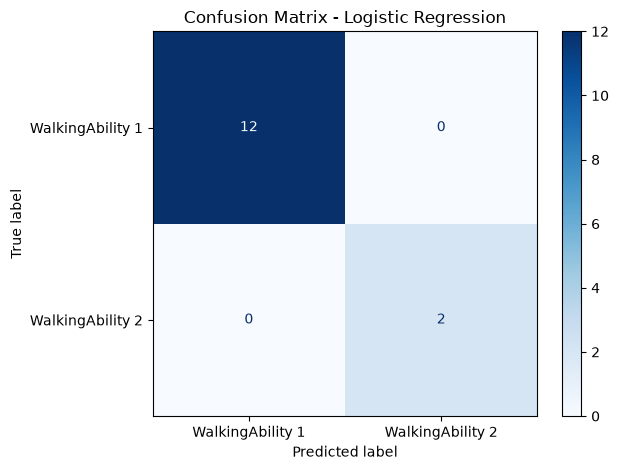

In [13]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y,
    y_pred,
    display_labels=["WalkingAbility 1", "WalkingAbility 2"],
    cmap="Blues"
)

plt.title("Confusion Matrix - Logistic Regression")
plt.tight_layout()

plt.savefig(
    "../images/confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 評価結果の考察

LOOCVによる評価では、14観測すべてを正しく分類し、Accuracyは1.00となった。
今回選択した加速度特徴量には、WalkingAbility 1と2を区別できる情報が
含まれている可能性が示された。

一方で、本データはWalkingAbility 1が12観測、WalkingAbility 2が2観測と
サンプル数が少なく、クラスにも大きな偏りがある。
特にWalkingAbility 2は2観測のみであるため、本結果だけから
未知データに対して高い分類性能を持つとは判断できない。

したがって、本分析ではモデル性能を確定することではなく、
加速度特徴量を用いて歩行能力の違いを捉えられる可能性を示した
探索的な結果として解釈する。

## 5. 個体単位でのデータ構成の確認

同一個体について異なる時点の観測が含まれている可能性があるため、
Observation_IDから個体IDを抽出し、個体ごとの観測数を確認する。

同一個体のデータが学習データと評価データの両方に含まれる場合、
個体固有の特徴をモデルが利用することで評価性能が高くなる可能性がある。

In [ ]:
# Observation_IDの末尾の日付部分を除いて個体IDを作成
df["Bird_ID"] = df["Observation_ID"].str.rsplit("_", n=1).str[0]

bird_summary = (
    df.groupby("Bird_ID")
    .agg(
        観測数=("Observation_ID", "count"),
        WalkingAbility種類数=("WalkingAbility", "nunique"),
        WalkingAbility=("WalkingAbility", lambda x: list(x))
    )
)

display(bird_summary)

print("個体数:", df["Bird_ID"].nunique())

## 6. 個体単位での交差検証

通常のLOOCVでは、同一個体の異なる時点のデータが
学習データと評価データの両方に含まれる場合がある。

そこで、個体IDをグループとして扱い、1個体分のデータをすべて評価用に除外する
Leave-One-Group-Out（LOGO）による評価を追加する。

これにより、学習時に使用していない個体に対しても
WalkingAbilityを分類できるかを確認する。

In [9]:
from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

groups = df["Bird_ID"]

logo = LeaveOneGroupOut()

y_pred_logo = cross_val_predict(
    model,
    X,
    y,
    groups=groups,
    cv=logo
)

print("個体単位CV Accuracy:", accuracy_score(y, y_pred_logo))

print("\n混同行列:")
print(confusion_matrix(y, y_pred_logo))

print("\n分類レポート:")
print(classification_report(y, y_pred_logo))

print("\n実際:")
print(y.values)

print("\n予測:")
print(y_pred_logo)

個体単位CV Accuracy: 1.0

混同行列:
[[12  0]
 [ 0  2]]

分類レポート:
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        12
           2       1.00      1.00      1.00         2

    accuracy                           1.00        14
   macro avg       1.00      1.00      1.00        14
weighted avg       1.00      1.00      1.00        14


実際:
[1 1 2 1 1 1 1 1 1 1 1 1 1 2]

予測:
[1 1 2 1 1 1 1 1 1 1 1 1 1 2]


## 7. ロジスティック回帰の係数確認

ロジスティック回帰の係数を確認し、
各特徴量がWalkingAbilityの分類にどのように寄与しているかを確認する。

係数が正の場合はWalkingAbility 2、
負の場合はWalkingAbility 1と判定する方向に影響する。

In [14]:
# 全データを使用してモデルを学習
model.fit(X, y)

# ロジスティック回帰部分を取得
logistic_model = model.named_steps["logistic"]

# 分類クラスを確認
print("分類クラス:", logistic_model.classes_)

# 各特徴量の係数を取得
coef_df = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": logistic_model.coef_[0]
})

# 係数の絶対値を計算
coef_df["AbsCoefficient"] = coef_df["Coefficient"].abs()

# 影響が大きい順に並べる
coef_df = coef_df.sort_values(
    "AbsCoefficient",
    ascending=False
)

display(coef_df)

分類クラス: [1 2]


,Feature,Coefficient,AbsCoefficient
2,SVM.Skewness,0.973789,0.973789
1,X_Dynamic_filt.AbsMean,-0.922761,0.922761
0,SVM.IQR,-0.804500,0.804500


### 係数の確認結果

ロジスティック回帰の係数を確認した結果、3特徴量すべてがWalkingAbilityの分類に寄与していた。

- SVM.Skewnessは正の係数を示し、値が大きいほどWalkingAbility 2と判定される方向に影響していた。
- X_Dynamic_filt.AbsMeanとSVM.IQRは負の係数を示し、値が小さいほどWalkingAbility 2と判定される方向に影響していた。

これらは特徴量分析で確認したWalkingAbility 1・2の分布の違いと一致している。

このことから、歩行能力が低下した個体では、加速度の大きさやばらつきだけでなく、
加速度分布の形状にも違いが現れている可能性が示された。

ただし、WalkingAbility 2の個体数が2個体と少ないため、
今回の結果だけで一般化することはできず、追加データによる検証が必要である。
また、WalkingAbilityと日齢・系統などの個体属性にも偏りがあるため、
今回確認された加速度特徴量の違いに、
歩行能力以外の要因が影響している可能性も考慮する必要がある。

## 8. モデル結果のまとめ

本分析では、鶏に装着された加速度センサから得られた特徴量を用いて、
WalkingAbility 1とWalkingAbility 2を分類するロジスティック回帰モデルを構築した。

特徴量分析の結果をもとに、
SVM.IQR、X_Dynamic_filt.AbsMean、SVM.Skewnessの3特徴量を説明変数として使用した。

交差検証では全14観測を正しく分類し、Accuracyは1.00となった。
また、同一個体のデータが学習用と評価用に混在する影響を確認するため、
個体単位でデータを分割した交差検証を行った場合も、全14観測を正しく分類した。

ロジスティック回帰の係数を確認すると、
SVM.Skewnessは値が大きいほどWalkingAbility 2、
X_Dynamic_filt.AbsMeanおよびSVM.IQRは値が小さいほどWalkingAbility 2と
判定される方向に影響していた。

この傾向は事前の特徴量分析で確認されたWalkingAbility別の分布とも一致しており、
加速度センサから得られる特徴量によって歩行能力の違いを捉えられる可能性が示された。

一方で、今回の分析対象は7個体14観測と少なく、
特にWalkingAbility 2は2個体・2観測のみである。
そのため、Accuracy 1.00を一般的な予測性能として解釈することはできない。

今後はより多くの個体・歩行能力レベルのデータを用いて検証することで、
加速度センサによる歩行能力低下の検知や、
鶏の健康・福祉状態を把握するためのモニタリングへの応用が期待される。